# Negative Fare analysis

In [31]:
import duckdb
df = duckdb.read_parquet('../raw/*/*.parquet')
df

┌──────────┬──────────────────────┬───────────────────────┬─────────────────┬───────────────┬────────────┬────────────────────┬──────────────┬──────────────┬──────────────┬─────────────┬────────┬─────────┬────────────┬──────────────┬───────────────────────┬──────────────┬──────────────────────┬─────────────┐
│ VendorID │ tpep_pickup_datetime │ tpep_dropoff_datetime │ passenger_count │ trip_distance │ RatecodeID │ store_and_fwd_flag │ PULocationID │ DOLocationID │ payment_type │ fare_amount │ extra  │ mta_tax │ tip_amount │ tolls_amount │ improvement_surcharge │ total_amount │ congestion_surcharge │ airport_fee │
│  int64   │      timestamp       │       timestamp       │     double      │    double     │   double   │      varchar       │    int64     │    int64     │    int64     │   double    │ double │ double  │   double   │    double    │        double         │    double    │        double        │   double    │
├──────────┼──────────────────────┼───────────────────────┼───────────

In [32]:
duckdb.sql("""
            SELECT 
            COUNT (*) AS total_rows,
            COUNT (*) FILTER (WHERE trip_distance < 0) AS negative_distance,
            COUNT (*) FILTER (WHERE fare_amount < 0) AS negative_fare,
            COUNT (*) FILTER (WHERE passenger_count < 0) AS negative_passengers,
            COUNT (*) FILTER (WHERE extra < 0) AS negative_extra,
            COUNT (*) FILTER (WHERE mta_tax < 0) AS negative_mta_tax,
            COUNT (*) FILTER (WHERE tip_amount < 0) AS negative_tip_amount,
            COUNT (*) FILTER (WHERE tolls_amount < 0) AS negative_tolls_amount,
            COUNT (*) FILTER (WHERE improvement_surcharge < 0) AS negative_improvement_surcharge,
            COUNT (*) FILTER (WHERE total_amount < 0) AS negative_total_amount,
            COUNT (*) FILTER (WHERE congestion_surcharge < 0) AS negative_congestion_surcharge,
            COUNT (*) FILTER (WHERE airport_fee < 0) AS negative_airport_fee
            FROM df
""").df()

,total_rows,negative_distance,negative_fare,negative_passengers,negative_extra,negative_mta_tax,negative_tip_amount,negative_tolls_amount,negative_improvement_surcharge,negative_total_amount,negative_congestion_surcharge,negative_airport_fee
0,167858646,0,4214194,0,1029414,1958014,8229,158379,2042089,2215654,1639288,344818


## Negative values

- Negative fare: `4214194`
- Negative extra: `1029414`
- Negative mta tax: `1958014`
- Negative tip amount: `8229`
- Negative tolls amount: `158379`
- Negative improvement surcharge: `2042089`
- Negative total amount: `2215654`
- Negative congestion surcharge: `1639288`
- Negative airport fee: `344818`

In [33]:
duckdb.sql("""
            SELECT * 
            FROM df
            WHERE 
            fare_amount < 0 
            
            """)

┌──────────┬──────────────────────┬───────────────────────┬─────────────────┬───────────────┬────────────┬────────────────────┬──────────────┬──────────────┬──────────────┬─────────────┬────────┬─────────┬────────────┬──────────────┬───────────────────────┬──────────────┬──────────────────────┬─────────────┐
│ VendorID │ tpep_pickup_datetime │ tpep_dropoff_datetime │ passenger_count │ trip_distance │ RatecodeID │ store_and_fwd_flag │ PULocationID │ DOLocationID │ payment_type │ fare_amount │ extra  │ mta_tax │ tip_amount │ tolls_amount │ improvement_surcharge │ total_amount │ congestion_surcharge │ airport_fee │
│  int64   │      timestamp       │       timestamp       │     double      │    double     │   double   │      varchar       │    int64     │    int64     │    int64     │   double    │ double │ double  │   double   │    double    │        double         │    double    │        double        │   double    │
├──────────┼──────────────────────┼───────────────────────┼───────────

In [34]:
neg_fairs = duckdb.sql("""
                        SELECT 
                            total_amount AS neg_total_amount,
                            payment_type
                        FROM
                            df
                        WHERE 
                            total_amount < 0 
                        """).df()
neg_fairs

,neg_total_amount,payment_type
0,-23.55,4
1,-20.80,4
2,-77.80,2
3,-7.80,2
4,-15.80,4
...,...,...
2215649,-20.37,0
2215650,-14.11,0
2215651,-4.75,0
2215652,-52.27,0


In [35]:
neg_fairs_count = neg_fairs["payment_type"].value_counts()
neg_fairs_count

payment_type
4    1250956
2     485403
3     306734
0     170659
1       1902
Name: count, dtype: int64

Note: you may need to restart the kernel to use updated packages.


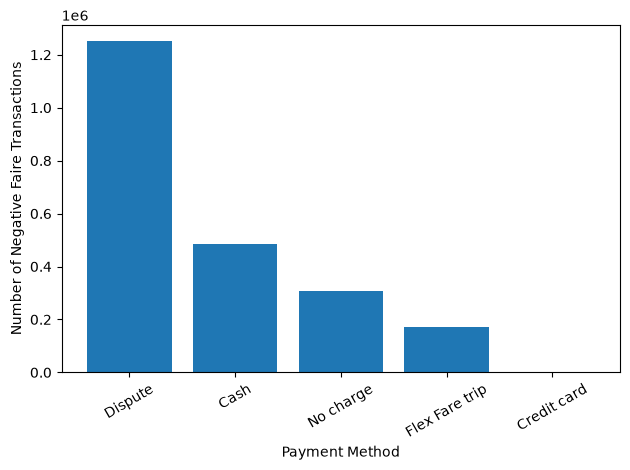

In [36]:
%pip install matplotlib
import matplotlib.pyplot as plt

payment_labels = {
    0: "Flex Fare trip",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Negotiated fare",
    6: "Voided trip"
}
plt.bar(
    neg_fairs_count.index.map(payment_labels),
    neg_fairs_count.values
)
plt.xlabel("Payment Method")
plt.ylabel("Number of Negative Faire Transactions")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

- From the avove graph it is Observed that:
     - The most negatieve faires were disputes
     - Least negatieve fairs were form Credit cards

## Negative fare Percentages

In [37]:
neg_fairs_percentage = (neg_fairs["payment_type"].value_counts(normalize=True)*100)
neg_fairs_percentage.index = neg_fairs_percentage.index.map(payment_labels)
neg_fairs_percentage.round(2)

payment_type
Dispute           56.46
Cash              21.91
No charge         13.84
Flex Fare trip     7.70
Credit card        0.09
Name: proportion, dtype: float64

# Fare Analysis

In [38]:
faire = duckdb.sql("""
                    SELECT 
                    *
                    FROM 
                        df
                    WHERE
                        total_amount > 0

""")
faire

┌──────────┬──────────────────────┬───────────────────────┬─────────────────┬───────────────┬────────────┬────────────────────┬──────────────┬──────────────┬──────────────┬─────────────┬────────┬─────────┬────────────┬──────────────┬───────────────────────┬──────────────┬──────────────────────┬─────────────┐
│ VendorID │ tpep_pickup_datetime │ tpep_dropoff_datetime │ passenger_count │ trip_distance │ RatecodeID │ store_and_fwd_flag │ PULocationID │ DOLocationID │ payment_type │ fare_amount │ extra  │ mta_tax │ tip_amount │ tolls_amount │ improvement_surcharge │ total_amount │ congestion_surcharge │ airport_fee │
│  int64   │      timestamp       │       timestamp       │     double      │    double     │   double   │      varchar       │    int64     │    int64     │    int64     │   double    │ double │ double  │   double   │    double    │        double         │    double    │        double        │   double    │
├──────────┼──────────────────────┼───────────────────────┼───────────

## What type of payment methods does most people use?

In [39]:
pay_methd = duckdb.sql("""
                        SELECT
                            payment_type AS payment_method
                        FROM
                            faire
                        """).df()
pay_methd

,payment_method
0,1
1,1
2,1
3,2
4,1
...,...
165618816,0
165618817,0
165618818,0
165618819,0


In [40]:
pay_type_count = pay_methd["payment_method"].value_counts()
pay_type_count

payment_method
1    121440208
2     23873652
0     18208693
4      1372803
3       723460
5            5
Name: count, dtype: int64

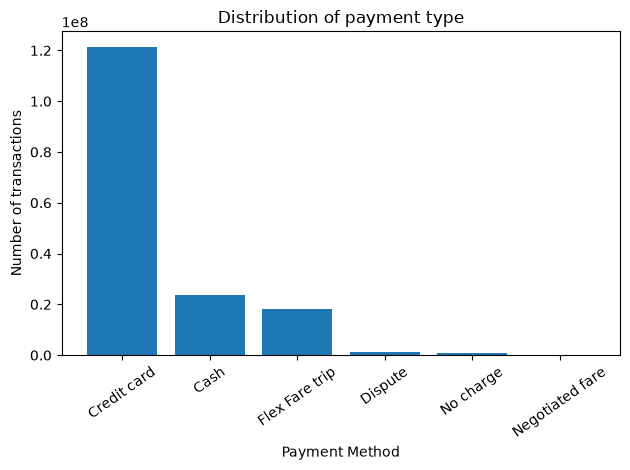

In [41]:
payment_labels = {
    0: "Flex Fare trip",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Negotiated fare",
    6: "Voided trip"
}

plt.bar(
    pay_type_count.index.map(payment_labels),
    pay_type_count.values
    )
plt.xlabel("Payment Method")
plt.ylabel("Number of transactions")
plt.title("Distribution of payment type")
plt.xticks(rotation=35)
plt.tight_layout()

In [46]:
pay_methd_pct = (pay_methd["payment_method"].value_counts(normalize=True)*100)
pay_methd_pct.index = pay_methd_pct.index.map(payment_labels)
pay_methd_pct.round(2)

payment_method
Credit card        73.33
Cash               14.41
Flex Fare trip     10.99
Dispute             0.83
No charge           0.44
Negotiated fare     0.00
Name: proportion, dtype: float64